# CNN on EuroSAT Dataset
Name: Asikqur Rahman
ID: 22-48971-3

In this assignment I build a CNN in PyTorch to classify satellite images into 10 classes. I train it, test it, plot the curves and save the weights.

## 1. Import Libraries

In [ ]:
!pip install -q torchsummary

In [ ]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, Subset
import torch
import torch.nn as nn

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
%matplotlib inline

# fix seed so the results are same every time
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## 2. Load and Explore Dataset
I used the **EuroSAT** dataset (satellite images from Sentinel-2).
- 27,000 colour images, 10 classes (AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake)
- Original image size is 64x64
- There is no separate train/test folder, so I split the data myself: 70% train, 15% validation, 15% test.

## 3. Data Preprocessing & Augmentation
- Images are resized to 32x32 to make training faster.
- Training images: random horizontal flip, rotation and colour jitter (to reduce overfitting). Satellite images look the same from any direction so flip and rotation are safe.
- Validation and test images: only resize and convert to tensor (no augmentation).

In [ ]:
size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),      # horizontal flip augmentation
    transforms.RandomRotation(15),          # rotate +-15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                   # convert PIL -> float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# same dataset loaded two times: one with augmentation, one without
data_aug   = datasets.EuroSAT("./data", transform=train_transform, download=True)
data_plain = datasets.EuroSAT("./data", transform=val_transform, download=True)
classes = data_aug.classes

In [ ]:
# split indices into train (70%), validation (15%), test (15%)
n = len(data_aug)
idx = torch.randperm(n, generator=torch.Generator().manual_seed(SEED)).tolist()
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_data = Subset(data_aug,   idx[:n_train])
val_data   = Subset(data_plain, idx[n_train:n_train + n_val])
test_data  = Subset(data_plain, idx[n_train + n_val:])

print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', data_aug.class_to_idx)

Dataset Summary
Train Data:  18900
Validation Data:  4050
Test Data:  4050
Classes and Indices:  {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


In [ ]:
# images per class
labels = np.array([y for _, y in data_plain.samples])
for i, c in enumerate(classes):
    print(c, ":", (labels == i).sum())

AnnualCrop : 3000
Forest : 3000
HerbaceousVegetation : 3000
Highway : 2500
Industrial : 2500
Pasture : 2000
PermanentCrop : 2500
Residential : 3000
River : 2500
SeaLake : 3000


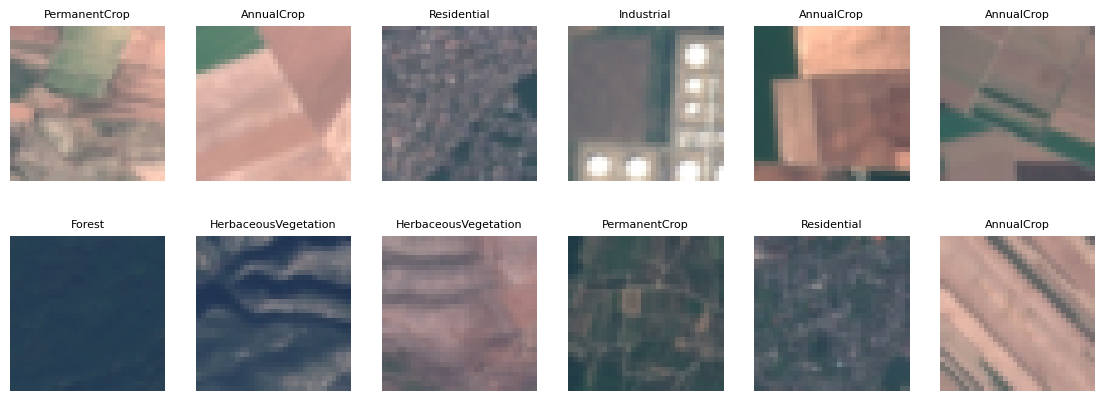

In [ ]:
# show some sample images
plt.figure(figsize=(14, 5))
for i in range(12):
    img, y = data_plain[random.randint(0, len(data_plain) - 1)]
    plt.subplot(2, 6, i + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(classes[y], fontsize=8)
    plt.axis("off")
plt.show()

### Hyperparameters
| Parameter | Value | Why |
|---|---|---|
| Image size | 32x32 | small and fast, still enough detail for this dataset |
| Batch size | 32 | stable training and fits in memory |
| Learning rate | 0.001 | normal starting value for Adam |
| Optimizer | Adam | learns fast, needs little tuning |
| Loss | CrossEntropyLoss | used for multi-class classification |
| Epochs | 15 | enough for this assignment, accuracy was still slowly rising |

In [ ]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 15
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture
The model has two parts.
- **Feature extraction:** 2 blocks of Conv -> ReLU -> MaxPool. Filters increase from 64 to 128, so the model learns simple patterns first (edges, colours) and then bigger patterns. MaxPool reduces the image size (32 -> 30 -> 15 -> 13 -> 6).
- **Classifier:** Flatten (128 x 6 x 6 = 4608) -> Linear 256 -> ReLU -> Linear 10. The last layer has 10 outputs, one for each class.

In [ ]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 10)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                   [-1, 10]           2,570
Total params: 1,258,122
Trainable params: 1,258,122
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

## 5. Training Loop with Validation
In each epoch the model trains on the training data and then I check it on the validation data. The weights of the best validation accuracy are saved.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
best_val_acc = 0

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    # save the best model
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

print("Best validation accuracy:", round(best_val_acc * 100, 2), "%")

Epoch [1/15] | Train Loss: 1.3500 | Train Accuracy: 49.41% | Val Loss: 1.1144 | Val Accuracy: 60.30%
Epoch [2/15] | Train Loss: 1.0164 | Train Accuracy: 62.84% | Val Loss: 0.8376 | Val Accuracy: 70.22%
Epoch [3/15] | Train Loss: 0.9192 | Train Accuracy: 66.54% | Val Loss: 0.8259 | Val Accuracy: 69.80%
Epoch [4/15] | Train Loss: 0.8427 | Train Accuracy: 69.29% | Val Loss: 0.7414 | Val Accuracy: 71.31%
Epoch [5/15] | Train Loss: 0.7977 | Train Accuracy: 71.27% | Val Loss: 0.6835 | Val Accuracy: 74.91%
Epoch [6/15] | Train Loss: 0.7553 | Train Accuracy: 72.81% | Val Loss: 0.6654 | Val Accuracy: 75.11%
Epoch [7/15] | Train Loss: 0.7174 | Train Accuracy: 73.93% | Val Loss: 0.8016 | Val Accuracy: 70.67%
Epoch [8/15] | Train Loss: 0.6918 | Train Accuracy: 74.59% | Val Loss: 0.6847 | Val Accuracy: 74.30%
Epoch [9/15] | Train Loss: 0.6645 | Train Accuracy: 76.07% | Val Loss: 0.5811 | Val Accuracy: 78.79%
Epoch [10/15] | Train Loss: 0.6463 | Train Accuracy: 76.67% | Val Loss: 0.6006 | Val Accura

## 6. Evaluate Model on Test Set
I load the best saved weights and test the model on the test data, which the model never saw in training.

In [ ]:
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        pred = model(x.to(device)).argmax(-1).cpu()
        all_preds.extend(pred.tolist())
        all_labels.extend(y.tolist())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print("Test Accuracy:", round(test_acc * 100, 2), "%")
print()
print(classification_report(all_labels, all_preds, target_names=classes))

Test Accuracy: 82.74 %

                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.79      0.83       472
              Forest       0.90      0.92      0.91       442
HerbaceousVegetation       0.77      0.71      0.74       458
             Highway       0.76      0.67      0.71       391
          Industrial       0.87      0.97      0.92       378
             Pasture       0.76      0.83      0.79       299
       PermanentCrop       0.69      0.74      0.71       379
         Residential       0.93      0.92      0.93       450
               River       0.74      0.78      0.76       375
             SeaLake       0.93      0.95      0.94       406

            accuracy                           0.83      4050
           macro avg       0.82      0.83      0.82      4050
        weighted avg       0.83      0.83      0.83      4050



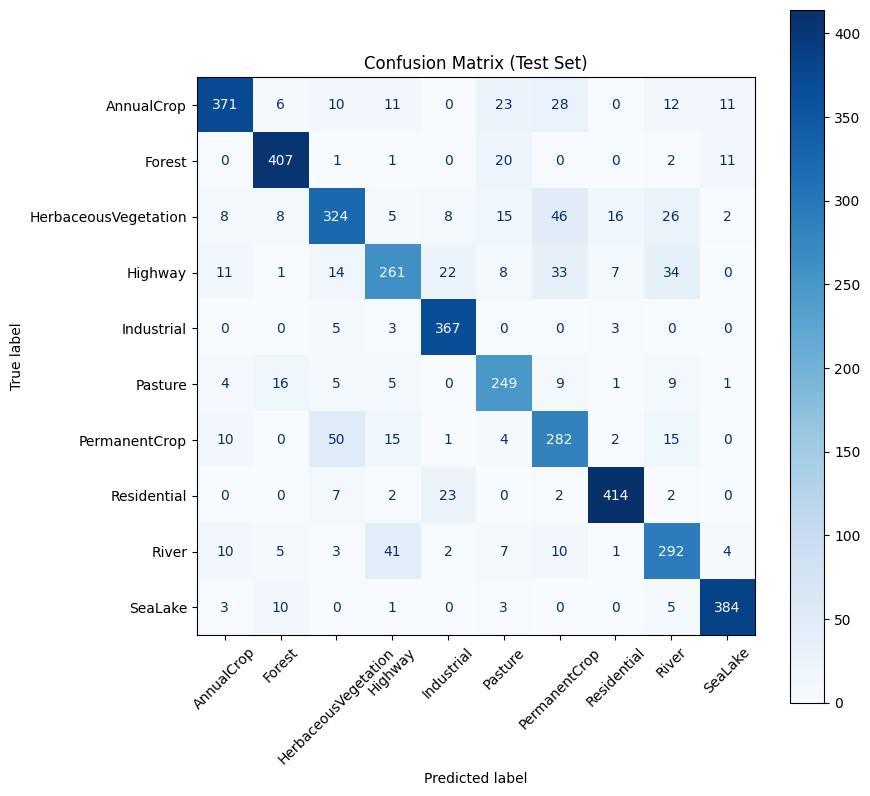

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix (Test Set)")
plt.show()

## 7. Visualizations (Loss/Accuracy Curves)

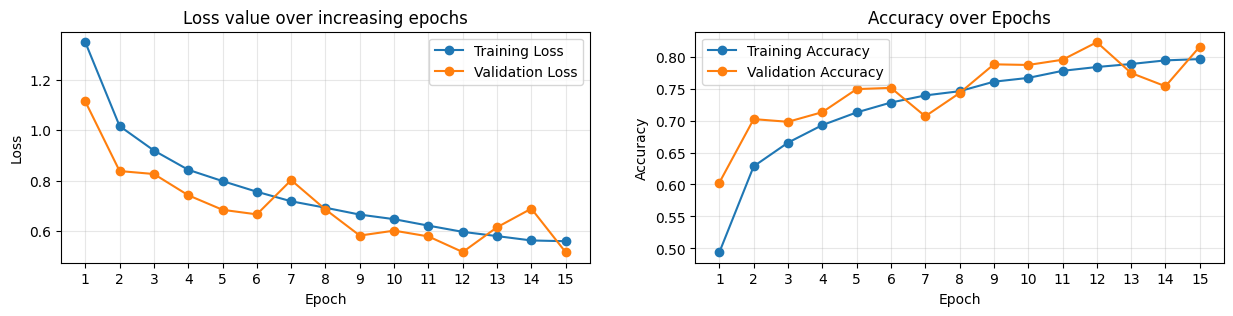

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Explanation of the curves:**
- Training loss went down from 1.35 to 0.56 and training accuracy went up from 49.4% to 79.6%.
- Validation loss went down from 1.11 to 0.51 and validation accuracy went up from 60.3% to 81.6%. The best validation accuracy was 82.25% at epoch 12.
- The validation curves are a bit noisy (for example the dips at epochs 7, 13 and 14), but they follow the training curves.
- Validation accuracy is similar to or higher than training accuracy. This is because the training images are augmented (flip, rotation, colour jitter) and the validation images are not. So there is no overfitting. The curves were still going up at epoch 15, so more epochs could help.

### Save and load the model weights

In [ ]:
torch.save(model.state_dict(), "cnn_eurosat.pth")
print("Saved, size:", round(os.path.getsize("cnn_eurosat.pth") / 1e6, 2), "MB")

# load it again in a new model to check
new_model, _, _ = get_model()
new_model.load_state_dict(torch.load("cnn_eurosat.pth", map_location=device))
new_model.eval()
print("Model loaded successfully")

Saved, size: 5.04 MB
Model loaded successfully


In [ ]:
# check that the loaded model gives the same results as the trained model
new_model.eval()
same = 0
total = 0
correct_new = 0

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        p_old = model(x).argmax(-1).cpu()
        p_new = new_model(x).argmax(-1).cpu()
        same += (p_old == p_new).sum().item()
        correct_new += (p_new == y).sum().item()
        total += len(y)

print("Predictions same as original model:", same, "/", total)
print("Loaded model test accuracy:", round(correct_new / total * 100, 2), "%")

Predictions same as original model: 4050 / 4050
Loaded model test accuracy: 82.74 %


## 8. Analysis & Discussion of Results
- The model got 82.74% accuracy on the test set and 82.25% on the validation set (best epoch). They are close, so the model works well on new images.
- From the confusion matrix, the model confuses PermanentCrop and HerbaceousVegetation the most (50 and 46 images). It also confuses River and Highway (41 and 34 images). These classes look similar from above, for example River and Highway are both long thin lines, and both crop and vegetation classes are green fields.
- Industrial (f1 0.92), Residential (0.93), SeaLake (0.94) and Forest (0.91) are easy for the model because they have clear colour and texture.
- The hardest classes were PermanentCrop (f1 0.71) and Highway (f1 0.71).
- Augmentation helped to keep the training and validation curves close.
- Adam with learning rate 0.001 worked fine without extra tuning.

## 9. Conclusions & Future Work
I built a CNN with 2 convolution blocks and trained it on EuroSAT. It got 82.74% test accuracy. The weights are saved in `cnn_eurosat.pth`.

In future I can try a deeper network, BatchNorm and Dropout, bigger images (64x64), a learning rate scheduler, or transfer learning (ResNet) to get higher accuracy.